# Delayed links: do the sensors look more curved once we look back in time?

`02_how_curved.ipynb` measured how curved the links between sensors are, and found them straight on both datasets. But it compared readings taken **at the same moment** only. In a real plant, one sensor often follows another after a delay: open a valve, and the temperature downstream moves a few minutes later. A link like that is invisible if you only compare readings from the same moment, and a curved one would have been missed.

This notebook repeats the measurement while also offering each sensor's prediction the **past readings of the other sensors**: 1, 2, 5 and 10 readings back.

**The answer in one line:** past readings make the chemical plant's links look somewhat *stronger*, and still straight. On the water pump they change nothing. No curved links appear on either.

**Words used here** (the rest are in `main.ipynb` and `02_how_curved.ipynb`)
- **Straight share**: the share of a sensor's movement that the other sensors predict using straight-line links. 0 means the other sensors say nothing about it; 1 means they predict it exactly.
- **Curved share**: the *extra* share predicted once the model is allowed to bend (a flexible model fitted on what the straight lines left over). About 0 means the links are straight. It can come out slightly below 0, when the flexible model picks up quirks that do not repeat; read that as 0.
- **Reading back**: one step into the past. On the plant a reading is taken every 3 minutes, so 10 readings back is 30 minutes ago. On the pump it is every second, so 10 readings back is 10 seconds ago.
- **Plausible range**: where a number could land with different data. Every range here is a 90% range from redrawing whole runs many times and recomputing the number.

**How the measurement is done**
- Each sensor is predicted from the *other* sensors only. Its own past is never used, because the question is about links between sensors, not about a sensor's own momentum.
- Past readings never reach across from one run into another.
- Every run is cut into five stretches of time. The models learn from four and are scored on the fifth, in turn, so every number comes from stretches the models did not see.
- All five sets of past readings in the table below are reported. None is picked as "the best".

The first run takes about 45 minutes and shows progress bars. Results are saved in `results/cache/`, so later runs take seconds.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import data, explore, plots, structure

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)

plant_runs = list(data.rieth_runs("fault_free_training", 20)[0])            # 20 fault-free runs of the plant
sessions = [r for r in data.load("skab").runs if len(r.fit) == 400]         # the pump's sessions
pump_runs = [r.fit - r.fit.mean(0) for r in sessions]                       # normal stretch of each, level removed
sensors = list(data.SKAB_INFO["sensor"])
print(f"Plant: {len(plant_runs)} runs of {len(plant_runs[0])} readings, {plant_runs[0].shape[1]} sensors, one reading every 3 minutes")
print(f"Pump:  {len(pump_runs)} sessions of {len(pump_runs[0])} readings, {pump_runs[0].shape[1]} sensors, one reading every second")
pd.Series(structure.LAG_SETS, name="past readings offered (readings back)").to_frame()

Plant: 20 runs of 500 readings, 52 sensors, one reading every 3 minutes
Pump:  33 sessions of 400 readings, 8 sensors, one reading every second


,past readings offered (readings back)
same moment only,()
+ 1 back,"(1,)"
"+ 1, 2 back","(1, 2)"
"+ 1, 2, 5 back","(1, 2, 5)"
"+ 1, 2, 5, 10 back","(1, 2, 5, 10)"


## 1. First, a check on made-up data

Before trusting the measurement, we try it on made-up sensors where we know the answer. One sensor follows another exactly **2 readings late**. In the first case it is a straight-line copy; in the second it is a curved function of it. The sensor it follows changes at random from reading to reading, so only the reading from exactly 2 steps back is any help.

If the measurement works, the follower should look unlinked until the reading from 2 steps back is offered. Then the link should show up as straight share in the first case and as curved share in the second.

In [2]:
structure.cached("lag_check", structure.lag_check)

straight link, 2 readings late               \
                                             straight share curved share   
other sensors' readings used                                               
same moment only                                     -0.001       -0.023   
+ 1 back                                             -0.002       -0.027   
+ 1, 2 back                                           0.919       -0.001   
+ 1, 2, 5 back                                        0.919       -0.001   

                             curved link, 2 readings late               
                                           straight share curved share  
other sensors' readings used                                            
same moment only                                   -0.002       -0.022  
+ 1 back                                           -0.002       -0.016  
+ 1, 2 back                                        -0.001        0.896  
+ 1, 2, 5 back                                     -0.001        0.896

**Reading this**
- With readings from the same moment, or from 1 step back, the follower looks unlinked: every share is about 0.
- Once the reading from 2 steps back is offered, the straight link shows as **0.92 straight share**, and the curved link as **0.90 curved share**. (Not 1.0, because the made-up follower also has some noise of its own.)
- Offering more past readings than needed (5 steps back) does no harm.

So a delayed link, straight or curved, is found when the right past reading is offered, and is labelled correctly.

## 2. The chemical plant

The data is 20 fault-free runs of the Tennessee Eastman plant (the Rieth files from `03_fresh_runs.ipynb`): 10,000 readings of 52 sensors, all at one operating setting.

Each row of the table offers the models more of the other sensors' past.

In [3]:
plant = structure.curvature_by_lag(plant_runs, data.TEP_CHANNELS, what="plant", cache="lags_plant")
structure.lag_table(plant)

,straight share,"straight, low","straight, high",curved share,"curved, low","curved, high",sensors gaining over 0.05 from curves,sensors gaining over 0.10 from curves
other sensors' readings used,,,,,,,,
same moment only,0.517,0.508,0.526,-0.005,-0.006,-0.005,0,0
+ 1 back,0.548,0.539,0.556,-0.004,-0.005,-0.004,0,0
"+ 1, 2 back",0.589,0.581,0.596,-0.004,-0.005,-0.004,0,0
"+ 1, 2, 5 back",0.59,0.582,0.597,-0.005,-0.005,-0.004,0,0
"+ 1, 2, 5, 10 back",0.59,0.582,0.597,-0.005,-0.006,-0.005,0,0


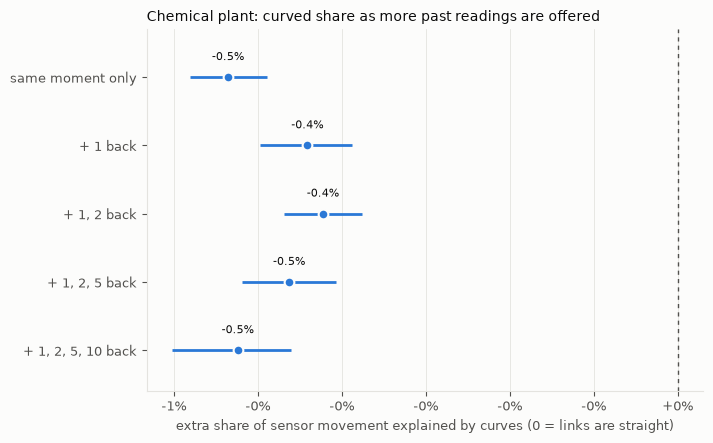

In [4]:
plots.curved_share(plant, title="Chemical plant: curved share as more past readings are offered");

**Reading this**
- **Straight share rises from 0.52 to 0.59.** With readings from the same moment, the other sensors predict 52% of a typical sensor's movement (range 0.51 to 0.53). Adding the readings from 1 and 2 steps back lifts that to 59% (range 0.58 to 0.60). Looking back further, to 15 or 30 minutes ago, adds nothing more.
- **Curved share stays at zero in every row**: about -0.005, with a range of -0.006 to -0.004. Not one of the 52 sensors gains even half a point from curves, in any row.
- For comparison, `02_how_curved.ipynb` measured 0.47 straight share on this plant from the 980 normal readings in the Braatz files. The 0.52 here comes from ten times as much data.

So the plant does have delayed links, worth about 7 points of straight share. They are straight too.

## 3. The water pump

The data is the normal stretch at the start of each recording session of the SKAB pump: 33 sessions of 400 readings, 8 sensors. Each session's average level is removed first, as in `02_how_curved.ipynb`, because the pump was run at different settings on different days and we want the links *within* a session.

In [5]:
pump = structure.curvature_by_lag(pump_runs, sensors, what="pump", cache="lags_pump")
structure.lag_table(pump)

,straight share,"straight, low","straight, high",curved share,"curved, low","curved, high",sensors gaining over 0.05 from curves,sensors gaining over 0.10 from curves
other sensors' readings used,,,,,,,,
same moment only,0.177,-12.296,0.261,-0.029,-2.357,0.943,1,0
+ 1 back,0.183,-14.871,0.271,-0.016,-0.803,1.866,1,0
"+ 1, 2 back",0.186,-16.154,0.28,-0.014,-0.127,2.018,2,0
"+ 1, 2, 5 back",0.187,-16.141,0.281,-0.025,-0.36,1.966,2,0
"+ 1, 2, 5, 10 back",0.188,-15.859,0.283,-0.037,-0.486,1.881,2,0


**Something is wrong with the ranges.** The curved share's range runs from far below -1 to about +1 or +2, which is meaningless for a share. The cause is one session.

The next table shows, for each sensor, the largest share of its movement that comes from a single session. If the sessions were alike, each would hold about 3% (1 in 33).

In [6]:
structure.movement_by_run(pump_runs, sensors, [r.name for r in sessions])

,largest share,run,even share
sensor,,,
Accelerometer1RMS,0.388,other/13,0.03
Accelerometer2RMS,0.249,other/13,0.03
Current,0.07,other/13,0.03
Pressure,0.037,other/1,0.03
Temperature,0.166,valve1/4,0.03
Thermocouple,0.414,other/11,0.03
Voltage,0.034,valve1/4,0.03
Volume Flow RateRMS,0.997,other/13,0.03


**One session holds 99.7% of the flow sensor's movement.** In session `other/13`, the "normal" stretch includes the pump being brought up to speed: the flow climbs from under 20 to about 125 litres a minute. In every other session the flow holds steady to within a couple of litres a minute.

So the flow sensor's numbers above are really numbers about that one session. When the redrawing happens to leave it out (about one draw in three), the result is measuring something else entirely, and the range blows up.

Below is the same measurement on the other 32 sessions. **Leaving the session out was decided after seeing the result above**, which is why both versions are shown.

In [7]:
rest = [X for X, r in zip(pump_runs, sessions) if r.name != "other/13"]
pump_rest = structure.curvature_by_lag(rest, sensors, what="pump without other/13", cache="lags_pump_without_13")
structure.lag_table(pump_rest)

,straight share,"straight, low","straight, high",curved share,"curved, low","curved, high",sensors gaining over 0.05 from curves,sensors gaining over 0.10 from curves
other sensors' readings used,,,,,,,,
same moment only,0.075,0.045,0.093,-0.037,-0.048,-0.02,1,0
+ 1 back,0.075,0.046,0.093,-0.025,-0.037,-0.009,1,0
"+ 1, 2 back",0.074,0.045,0.091,-0.031,-0.043,-0.013,1,0
"+ 1, 2, 5 back",0.072,0.043,0.089,-0.037,-0.052,-0.016,1,0
"+ 1, 2, 5, 10 back",0.069,0.041,0.086,-0.054,-0.071,-0.03,1,0


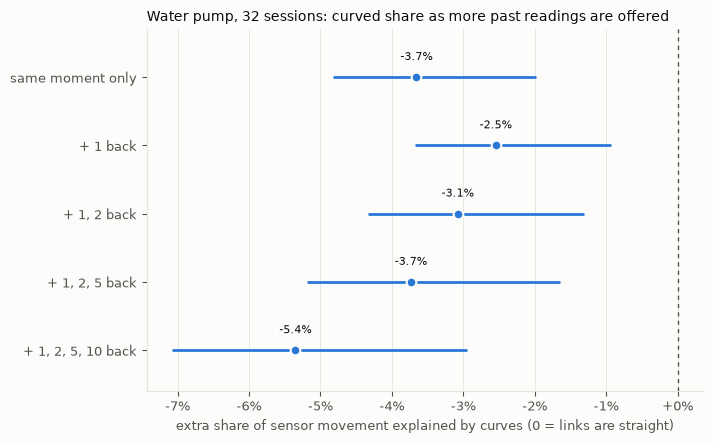

In [8]:
plots.curved_share(pump_rest, title="Water pump, 32 sessions: curved share as more past readings are offered");

**Reading this** (32 sessions)
- **Straight share is about 0.07 and does not move with past readings**: 0.075 with readings from the same moment (range 0.05 to 0.09), 0.069 with all the past readings (range 0.04 to 0.09). This agrees with the 0.07 that `02_how_curved.ipynb` found. Within a session, the pump's sensors say little about each other, with or without delays up to 10 seconds.
- **Curved share is slightly below zero in every row**, between -0.03 and -0.05, with ranges that stay below zero. The flexible model makes predictions a little *worse* here. Section 4 shows this comes from the two temperature sensors.
- One sensor of the eight gains more than 5 points from curves (the motor voltage, about 6 points). None gains more than 10.

With all 33 sessions the straight share looked higher (0.18). That was the flow sensor in the one start-up session, not a link that holds across sessions.

## 4. Which sensors gain from past readings?

First the plant: the ten sensors whose straight share rises most when past readings are offered. Then all eight pump sensors (32 sessions). The last three columns of each table are the sensor's curved share and its range, with all the past readings offered.

In [9]:
most = "+ 1, 2, 5, 10 back"
now, late = plant["same moment only"]["table"], plant[most]["table"]
print("Plant: largest share of any sensor's movement held by one run:",
      explore.tidy(structure.movement_by_run(plant_runs, data.TEP_CHANNELS)["largest share"].max()), "(an even split is 0.05)")
print("Plant: largest curved share of any sensor, over all five rows:",
      explore.tidy(max(s["table"]["curved"].max() for s in plant.values())))
display(pd.concat([data.TEP_INFO.set_index("variable")["what it measures"],
                   now["straight"].rename("straight, same moment"), late["straight"].rename("straight, with past readings"),
                   (late["straight"] - now["straight"]).rename("gain in straight share"),
                   late[["curved", "curved_low", "curved_high"]]], axis=1)
        .sort_values("gain in straight share", ascending=False).head(10))
pd.concat([data.SKAB_INFO.set_index("sensor")["what it measures"],
           pump_rest["same moment only"]["table"]["straight"].rename("straight, same moment"),
           pump_rest[most]["table"].rename(columns={"straight": "straight, with past readings"})], axis=1)

Plant: largest share of any sensor's movement held by one run: 0.111 (an even split is 0.05)
Plant: largest curved share of any sensor, over all five rows: 0.003


,what it measures,"straight, same moment","straight, with past readings",gain in straight share,curved,curved_low,curved_high
XMEAS(3),E feed (stream 3),0.221,0.977,0.756,0,-0.001,0
XMV(2),E feed flow,0.223,0.978,0.755,0,-0.001,0
XMV(1),D feed flow,0.385,0.976,0.591,0,-0.001,0
XMEAS(2),D feed (stream 2),0.389,0.977,0.588,-0.001,-0.001,0
XMEAS(22),Separator cooling water outlet temp,0.652,0.953,0.301,0,0,0.001
XMEAS(11),Separator temperature,0.851,0.988,0.137,0,0,0
XMEAS(21),Reactor cooling water outlet temp,0.636,0.747,0.111,-0.001,-0.001,0
XMEAS(38),Product: % of component E,0.621,0.714,0.094,-0.009,-0.012,-0.006
XMEAS(9),Reactor temperature,0.48,0.562,0.082,-0.004,-0.005,-0.003
XMEAS(35),Purge gas: % of component G,0.351,0.417,0.066,-0.008,-0.012,-0.006


,what it measures,"straight, same moment","straight, with past readings",curved,curved_low,curved_high
sensor,,,,,,
Accelerometer1RMS,"Vibration of the pump, sensor 1",0.193,0.171,-0.067,-0.159,0.016
Accelerometer2RMS,"Vibration of the pump, sensor 2",0.203,0.205,0.028,0.006,0.054
Current,Electric current drawn by the motor,0.14,0.136,0.009,0.002,0.015
Pressure,Water pressure just after the pump,-0.001,-0.003,-0.008,-0.011,-0.005
Temperature,Temperature of the motor body,-0.009,-0.012,-0.269,-0.366,-0.132
Thermocouple,Temperature of the water in the loop,-0.061,-0.081,-0.165,-0.203,-0.103
Voltage,Voltage across the motor,0.141,0.148,0.061,0.054,0.068
Volume Flow RateRMS,How fast water flows round the loop,-0.005,-0.009,-0.016,-0.026,-0.006


**Reading this**

*Plant*
- The gain comes from a handful of sensors. The clearest are **two feed streams and the valves that control them** (the D feed and the E feed). At the same moment a feed's flow reading and its valve look only loosely linked (0.22 to 0.39). With the readings from one and two steps back, each predicts the other almost exactly (0.98). The most likely reason: a flow meter and its valve are tied together by a control loop, which takes a reading or two to respond.
- The cooling-water and separator temperatures gain too, probably because heat takes a few minutes to arrive.
- For every one of these sensors the curved share is zero to within a point. The delayed links are straight.
- No single run dominates any plant sensor, so the ranges here can be trusted.

*Pump*
- No pump sensor gains anything from past readings.
- The **two temperature sensors** have clearly negative curved shares (about -0.27 and -0.17). Temperatures creep slowly during a session. The flexible model memorises the creep in the stretches it learns from, and that pattern does not repeat in the stretch it is scored on. This is the flexible model failing, not a curved link.
- The **motor voltage** is the one sensor with a small curved gain that is steady: about 6 points, range 5 to 7. It is below the 10-point mark used in the plan.

## 5. What this means

| | Straight share, same moment | Straight share, with past readings | Curved share, with past readings | Sensors gaining over 10 points from curves |
|---|---|---|---|---|
| Chemical plant (20 runs, 52 sensors) | 0.52 (0.51 to 0.53) | 0.59 (0.58 to 0.60) | -0.005 (-0.006 to -0.005) | 0 of 52 |
| Water pump (32 sessions, 8 sensors) | 0.075 (0.05 to 0.09) | 0.069 (0.04 to 0.09) | -0.054 (-0.071 to -0.030) | 0 of 8 |

"With past readings" is the last row of each table above (1, 2, 5 and 10 readings back). The other rows tell the same story.

- **Looking back in time does not uncover curved links** on either dataset. The finding from `02_how_curved.ipynb` stands: at one operating setting, the links between these sensors are straight.
- **The plant has delayed links, and they are straight.** They add about 7 points of straight share. A detector built on straight links could in principle use them. That has not been tried here.
- **The pump has no delayed links** within 10 seconds.

**What this does not cover**
- Delays longer than 10 readings (30 minutes on the plant, 10 seconds on the pump).
- A sensor's own past. It was left out on purpose.
- More than one operating setting. Both datasets here sit at a single setting (the pump's settings differ between sessions, but each session's level was removed). Links that change with the setting are where curves should show, and that is what the next two datasets are for: the Cranfield flow rig and the multi-mode version of this plant.

**A caution carried forward.** Ranges that come from redrawing runs can be wrecked by a single unusual run, as the pump showed. `structure.movement_by_run` checks for this, and will be run on the next datasets before their ranges are trusted.